In [1]:
import numpy as np
import matplotlib.pyplot as plt
import os
from matplotlib.ticker import AutoMinorLocator, MaxNLocator

tab10 = plt.get_cmap("tab10").colors
palette = [
    tab10[0],  # blue
    tab10[9],  # cyan
    tab10[2],  # green
    tab10[8],  # olive
    tab10[1],  # orange
    tab10[3],  # red
    tab10[4],  # purple
    tab10[6],  # pink
    tab10[5],  # brown
    tab10[7],  # gray
]

from Utils.elm_classifier import elm_classifier

plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",

    "font.size": 18,
    "axes.labelsize": 18,
    "axes.titlesize": 18,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 15,

    "axes.grid": True,
    "grid.linestyle": ":",
    "grid.alpha": 0.5,
    "axes.unicode_minus": True,
})

# HNLF

## Experimental data

In [2]:
save_dir = r"data\HNLF_exp_MNIST"

# =========================
# Allocation of arrays
# =========================
ACC_TRAIN_EXP_HNLF, ACC_TEST_EXP_HNLF = [], []
MSE_TRAIN_EXP_HNLF, MSE_TEST_EXP_HNLF = [], []
CE_TRAIN_EXP_HNLF,  CE_TEST_EXP_HNLF  = [], []
HTC_EXP_HNLF  = []

# =========================
# Labels
# =========================
YTrain_d = np.load(os.path.join(save_dir, "YTrain_d.npy"))
YTest_d  = np.load(os.path.join(save_dir, "YTest_d.npy"))

# =========================
# Loop over nonlinear parameter N
# =========================
for ii in range(9):

    # -------------------------------------------------
    # Loading spectra
    # -------------------------------------------------
    X_train_interp = np.load(os.path.join(save_dir, f"Ispec_train_{ii+1}.npy"))
    X_test_interp  = np.load(os.path.join(save_dir, f"Ispec_test_{ii+1}.npy"))
    
    
    # -------------------------------------------------
    # ELM classifier
    # -------------------------------------------------
    results = elm_classifier(
        Ispec_train=X_train_interp,
        Ispec_test=X_test_interp,
        YTrain=YTrain_d,
        YTest=YTest_d,
        normalize=False,
        lambda_reg=None,
        scan_lambda=True,
        n_lambda=100,
        lambda_min=1e-12,
        lambda_max=1e6,
        objective='mse',
        PCvar=None,
        validation=True,
        permutation=True,
        val_size=1000,
        sampling = 600,
        verbose=True)

    ACC_TRAIN_EXP_HNLF.append(results["train_accuracy"])
    ACC_TEST_EXP_HNLF.append(results["test_accuracy"])
    MSE_TRAIN_EXP_HNLF.append(results["train_mse"])
    MSE_TEST_EXP_HNLF.append(results["test_mse"])
    CE_TRAIN_EXP_HNLF.append(results["train_crossent"])
    CE_TEST_EXP_HNLF.append(results["test_crossent"])
    HTC_EXP_HNLF.append(results["HTC_criterion"])
    
    print()
    print()

HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 1.874e-03
Train Acc: 76.38%
Test Acc: 74.80%
Train CE: 1.941725
Test CE: 1.942129
Train MSE: 0.050674
Test MSE: 0.051546
HTC: 10.805259


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 3.511e-06
Train Acc: 79.86%
Test Acc: 78.70%
Train CE: 1.943975
Test CE: 1.947116
Train MSE: 0.051804
Test MSE: 0.053406
HTC: 8.453140


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 1.520e-06
Train Acc: 87.16%
Test Acc: 86.50%
Train CE: 1.792943
Test CE: 1.796288
Train MSE: 0.035562
Test MSE: 0.036424
HTC: 18.148456


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 8.111e-06
Train Acc: 82.62%
Test Acc: 81.70%
Train CE: 1.852256
Test CE: 1.851662
Train MSE: 0.041968
Test MSE: 0.043237
HTC: 13.408282


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 6

## Simulation data

In [3]:
save_dir = r"data\HNLF_sim_MNIST"

# =========================================================
# PARAMETERS
# =========================================================
phases = [0.25, 0.5, 0.625]
ALL_RESULTS_2 = {}
eps = 1e-12

Nav   = 1 # if you want to average the data
shape = (10, Nav)

# =========================================================
# Labels
# =========================================================
YTrain_d = np.load(os.path.join(save_dir, "YTrain_d.npy"))
YTest_d  = np.load(os.path.join(save_dir, "YTest_d.npy"))

# =========================================================
# Loop over phase encoding factors
# =========================================================
for idx_phase in phases:

    print(f"\n===== RUNNING idx_phase = {idx_phase} =====\n")

    ACC_TRAIN = np.zeros(shape)
    ACC_TEST  = np.zeros(shape)
    MSE_TRAIN = np.zeros(shape)
    MSE_TEST  = np.zeros(shape)
    CE_TRAIN  = np.zeros(shape)
    CE_TEST   = np.zeros(shape)
    HTC       = np.zeros(shape)
    
    # =========================================================
    # Loop over nonlinear parameter N
    # =========================================================
    for jj in range(Nav):
        
        for ii in range(10):

            # -------------------------------------------------
            # Loading spectra
            # -------------------------------------------------
            X_train = np.load(os.path.join(save_dir,
                              f"Ispec_train_N_{ii+1}_a_{idx_phase}.npy"))
            X_test  = np.load(os.path.join(save_dir,
                              f"Ispec_test_N_{ii+1}_a_{idx_phase}.npy"))

            # -------------------------------------------------
            # ELM classifier
            # -------------------------------------------------
            res = elm_classifier(
                X_train,
                X_test,
                YTrain=YTrain_d,
                YTest=YTest_d,
                normalize=False,
                lambda_reg=None,
                scan_lambda=True,
                n_lambda=100,
                lambda_min=1e-12,
                lambda_max=1e6,
                objective='mse',
                PCvar=None,
                validation=True,
                permutation=True,
                val_size=1000,
                sampling = 600,
                verbose=True)

            # -------------------------------------------------
            # Store
            # -------------------------------------------------
            ACC_TRAIN[ii, jj] = res["train_accuracy"]
            ACC_TEST[ii, jj]  = res["test_accuracy"]
            MSE_TRAIN[ii, jj] = res["train_mse"]
            MSE_TEST[ii, jj]  = res["test_mse"]
            CE_TRAIN[ii, jj]  = res["train_crossent"]
            CE_TEST[ii, jj]   = res["test_crossent"]
            HTC[ii, jj]       = res["HTC_criterion"]
            
            print()
            print()

    # =========================================================
    # Save into dict.
    # =========================================================
    ALL_RESULTS_2[idx_phase] = {
        "ACC_TRAIN":      ACC_TRAIN.copy(),
        "ACC_TEST":       ACC_TEST.copy(),
        "MSE_TRAIN":      MSE_TRAIN.copy(),
        "MSE_TEST":       MSE_TEST.copy(),
        "CE_TRAIN":       CE_TRAIN.copy(),
        "CE_TEST":        CE_TEST.copy(),
        "HTC":            HTC.copy(),
        "log_HTC":        np.log(HTC     + eps),
        "log_mse_train":  np.log(MSE_TRAIN + eps),
        "log_mse_test":   np.log(MSE_TEST  + eps),
    }
    


===== RUNNING idx_phase = 0.25 =====

HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 8.111e-06
Train Acc: 81.80%
Test Acc: 83.60%
Train CE: 1.900105
Test CE: 1.891259
Train MSE: 0.047165
Test MSE: 0.046505
HTC: 12.731098


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 8.111e-06
Train Acc: 84.45%
Test Acc: 85.60%
Train CE: 1.861666
Test CE: 1.854935
Train MSE: 0.042773
Test MSE: 0.043103
HTC: 14.520133


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 4.329e-05
Train Acc: 85.35%
Test Acc: 86.40%
Train CE: 1.832413
Test CE: 1.824882
Train MSE: 0.039691
Test MSE: 0.039007
HTC: 16.577735


HTrain - 9000 samples, 600 neurons
HTest  - 1000 samples, 600 neurons
Features: 600
Lambda: 1.520e-04
Train Acc: 87.01%
Test Acc: 86.90%
Train CE: 1.815495
Test CE: 1.802660
Train MSE: 0.037789
Test MSE: 0.037402
HTC: 18.292601


HTrain - 9000 samples, 600 neurons
HTest 

## Final figure for HNLF: experimental data + numerical simulations

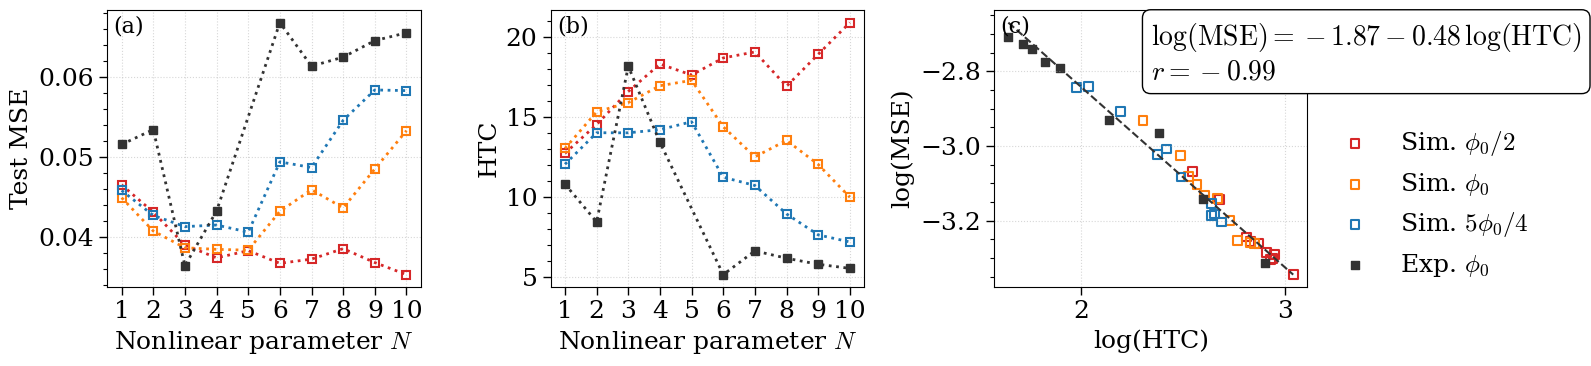

In [4]:
eps = 1e-12
Narray_match = np.asarray([1, 2, 3, 4, 5, 6, 7, 8, 9, 10.0])
Narray_match0 = np.delete(Narray_match, 4)

# ------------------------------------------------
# Extract results from dictionary
# ------------------------------------------------
res_025  = ALL_RESULTS_2[0.25]
res_050  = ALL_RESULTS_2[0.5]
res_0625 = ALL_RESULTS_2[0.625]

# ------------------------------------------------
# Experimental data
# ------------------------------------------------
log_HTC_exp_hnlf = np.log(np.asarray(HTC_EXP_HNLF) + eps)
log_mse_test_exp_hnlf = np.log(np.asarray(MSE_TEST_EXP_HNLF) + eps)

# ------------------------------------------------
# Figure
# ------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
(ax1, ax2, ax3) = axs

# =========================================================
# (1) MSE test vs N
# =========================================================
ax1.plot(Narray_match, np.mean(res_025["MSE_TEST"], axis=1),
         marker='s', linewidth=2,
         label=fr'$\phi_0/2$', color=palette[5], markeredgewidth = 1.5, markerfacecolor='none', linestyle = ':')

ax1.plot(Narray_match, np.mean(res_050["MSE_TEST"], axis=1),
         marker='s', linewidth=2,
         label=fr'$\phi_0$', color=palette[4], markeredgewidth = 1.5, markerfacecolor='none', linestyle = ':')

ax1.plot(Narray_match, np.mean(res_0625["MSE_TEST"], axis=1),
         marker='s', linewidth=2,
         label=fr'$3\phi_0/2$', color=palette[0], markeredgewidth = 1.5, markerfacecolor='none', linestyle = ':')

ax1.plot(Narray_match0, MSE_TEST_EXP_HNLF,
         marker='s', linestyle=':', linewidth=2,
         label=fr'Exp. $\phi_0$', color='0.2')

ax1.set_xlabel("Nonlinear parameter $N$")
ax1.set_ylabel("Test MSE")



# =========================================================
# (2) HTC vs N
# =========================================================
ax2.plot(Narray_match, np.mean(res_025["HTC"], axis=1),
         marker='s', linewidth=2,
         label=fr'$\phi_0/2$', color=palette[5], markeredgewidth = 1.5, markerfacecolor='none', linestyle = ':')

ax2.plot(Narray_match, np.mean(res_050["HTC"], axis=1),
         marker='s', linewidth=2,
         label=fr'$\phi_0$', color=palette[4], markeredgewidth = 1.5, markerfacecolor='none', linestyle = ':')

ax2.plot(Narray_match, np.mean(res_0625["HTC"], axis=1),
         marker='s', linewidth=2,
         label=fr'$3\phi_0/2$', color=palette[0], markeredgewidth = 1.5, markerfacecolor='none', linestyle = ':')

ax2.plot(Narray_match0, HTC_EXP_HNLF,
         marker='s', linestyle=':', linewidth=2,
         label=fr'Exp. $\phi_0$', color='0.2')

ax2.set_xlabel("Nonlinear parameter $N$")
ax2.set_ylabel(r"HTC")

# =========================================================
# (3) Log-log HTC vs MSE (LINEAR + PEARSON)
# =========================================================

# ---- Extract logs ----
log_HTC_250 = res_025["log_HTC"]
log_HTC_500 = res_050["log_HTC"]
log_HTC_625 = res_0625["log_HTC"]

log_mse_250 = res_025["log_mse_test"]
log_mse_500 = res_050["log_mse_test"]
log_mse_625 = res_0625["log_mse_test"]

# ---- Mean over Nav ----
log_HTC_250_mean = np.mean(log_HTC_250, axis=1)
log_HTC_500_mean = np.mean(log_HTC_500, axis=1)
log_HTC_625_mean = np.mean(log_HTC_625, axis=1)

log_mse_250_mean = np.mean(log_mse_250, axis=1)
log_mse_500_mean = np.mean(log_mse_500, axis=1)
log_mse_625_mean = np.mean(log_mse_625, axis=1)

# ---- Concatenate ALL ----
log_HTC_all = np.concatenate([
    log_HTC_250_mean,
    log_HTC_500_mean,
    log_HTC_625_mean,
    log_HTC_exp_hnlf
])

log_mse_all = np.concatenate([
    log_mse_250_mean,
    log_mse_500_mean,
    log_mse_625_mean,
    log_mse_test_exp_hnlf
])

# ---- Linear regression ----
slope, intercept = np.polyfit(log_HTC_all, log_mse_all, 1)

x_fit = np.linspace(min(log_HTC_all), max(log_HTC_all), 200)
y_fit = intercept + slope * x_fit

# ---- Pearson correlation ----
pearson_r = np.corrcoef(log_HTC_all, log_mse_all)[0, 1]

# ---- Plot line ----
ax3.plot(x_fit, y_fit, linestyle='--', color='0.2', linewidth=1.5)

# ---- Scatter plot ----
ax3.scatter(log_HTC_250_mean, log_mse_250_mean,
            marker='s', s=40, label=fr'Sim. $\phi_0/2$', color=palette[5], facecolor = 'None', linewidth = 1.5)

ax3.scatter(log_HTC_500_mean, log_mse_500_mean,
            marker='s', s=40, label=fr'Sim. $\phi_0$', color=palette[4], facecolor = 'None', linewidth = 1.5)

ax3.scatter(log_HTC_625_mean, log_mse_625_mean,
            marker='s', s=40, label=fr'Sim. $5\phi_0/4$', color=palette[0], facecolor = 'None', linewidth = 1.5)

ax3.scatter(log_HTC_exp_hnlf, log_mse_test_exp_hnlf,
            marker='s', s=40, label=fr'Exp. $\phi_0$', color='0.2')

ax3.set_xlabel(r'log(HTC)')
ax3.set_ylabel(r'log(MSE)')

ax3.legend(loc='center left',
    bbox_to_anchor=(1, 0.3),
    frameon=False,
    fontsize = 18)

# ---- Equation ----
eq_text = (
    r"$\log(\mathrm{MSE}) = "
    + (f"+ {intercept:.2f}" if intercept >= 0 else f"- {abs(intercept):.2f}")
    + f"{slope:.2f}"
    + r"\,\log(\mathrm{HTC})$"
    + "\n"
    + rf"$r = {pearson_r:.2f}$"
)

ax3.text(
    0.5, 0.96, eq_text,
    transform=ax3.transAxes,
    fontsize=20,
    verticalalignment='top',
    bbox=dict(boxstyle="round", facecolor="white", alpha=1)
)

for ax in axs.flat:
    ax.minorticks_on()
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which='major', length=6, width=1)
    ax.tick_params(which='minor', length=3, width=0.8)

for ax in [ax1, ax2, ax3]:
    ax.xaxis.set_minor_locator(plt.NullLocator())
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))

# Panel labels
labels = ['(a)', '(b)', '(c)']
for ax, label in zip(axs.flat, labels):
    ax.text(0.02, 0.98, label,
            transform=ax.transAxes,
            fontsize=16,
            va='top')

plt.tight_layout()
plt.savefig("Figure_hnlf.pdf", bbox_inches='tight')
plt.savefig("Figure_hnlf.png", bbox_inches='tight', dpi=400)

plt.show()

# VCSEL: Experimental data

In [5]:
save_dir = r"data\VCSEL_exp_MNIST"

# =========================
# Allocation of arrays
# =========================
ACC_TRAIN_EXP_VCS, ACC_TEST_EXP_VCS = [], []
MSE_TRAIN_EXP_VCS, MSE_TEST_EXP_VCS = [], []
CE_TRAIN_EXP_VCS,  CE_TEST_EXP_VCS  = [], []
HTC_EXP_VCS  = []

# =========================
# Labels
# =========================
YTrain_d = np.load(os.path.join(save_dir, "YTrain_d.npy"))
YTest_d  = np.load(os.path.join(save_dir, "YTest_d.npy"))

# =========================
# Loop over wavelength
# =========================
for ii in range(50):

    # -------------------------------------------------
    # Loading flattened data
    # -------------------------------------------------
    X_train_interp = np.load(os.path.join(save_dir, f"Ispec_train_{ii+1}.npy"))
    X_test_interp  = np.load(os.path.join(save_dir, f"Ispec_test_{ii+1}.npy"))
    
    
    # -------------------------------------------------
    # ELM classifier
    # -------------------------------------------------
    results = elm_classifier(
        Ispec_train=X_train_interp,
        Ispec_test=X_test_interp,
        YTrain=YTrain_d,
        YTest=YTest_d,
        normalize=False,
        lambda_reg=None,
        scan_lambda=True,
        n_lambda=100,
        lambda_min=1e-12,
        lambda_max=1e6,
        objective='mse',
        PCvar=None,
        validation=True,
        permutation=True,
        val_size=500,
        sampling=600,
        verbose=True)

    ACC_TRAIN_EXP_VCS.append(results["train_accuracy"])
    ACC_TEST_EXP_VCS.append(results["test_accuracy"])
    MSE_TRAIN_EXP_VCS.append(results["train_mse"])
    MSE_TEST_EXP_VCS.append(results["test_mse"])
    CE_TRAIN_EXP_VCS.append(results["train_crossent"])
    CE_TEST_EXP_VCS.append(results["test_crossent"])
    HTC_EXP_VCS.append(results["HTC_criterion"])    
    print()
    print()

HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.874e+03
Train Acc: 92.77%
Test Acc: 89.20%
Train CE: 1.753913
Test CE: 1.777786
Train MSE: 0.028866
Test MSE: 0.032742
HTC: 27.268514


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.874e+03
Train Acc: 91.95%
Test Acc: 87.60%
Train CE: 1.771547
Test CE: 1.802230
Train MSE: 0.030533
Test MSE: 0.035366
HTC: 25.192857


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.874e+03
Train Acc: 93.33%
Test Acc: 87.80%
Train CE: 1.747412
Test CE: 1.781392
Train MSE: 0.028167
Test MSE: 0.033765
HTC: 27.137300


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.874e+03
Train Acc: 92.53%
Test Acc: 87.80%
Train CE: 1.763209
Test CE: 1.791767
Train MSE: 0.029636
Test MSE: 0.034054
HTC: 25.527685


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
L

Features: 600
Lambda: 1.874e+03
Train Acc: 93.83%
Test Acc: 91.40%
Train CE: 1.707895
Test CE: 1.727822
Train MSE: 0.024337
Test MSE: 0.027751
HTC: 33.122744


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.233e+03
Train Acc: 93.97%
Test Acc: 90.20%
Train CE: 1.707928
Test CE: 1.730804
Train MSE: 0.024575
Test MSE: 0.028594
HTC: 32.240922


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.874e+03
Train Acc: 94.23%
Test Acc: 90.80%
Train CE: 1.706947
Test CE: 1.725224
Train MSE: 0.024171
Test MSE: 0.027810
HTC: 33.629415


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.233e+03
Train Acc: 93.97%
Test Acc: 90.80%
Train CE: 1.711551
Test CE: 1.739410
Train MSE: 0.024863
Test MSE: 0.029383
HTC: 32.104702


HTrain - 4500 samples, 600 neurons
HTest  - 500 samples, 600 neurons
Features: 600
Lambda: 1.874e+03
Train Acc: 93.80%
Test Acc: 92.20%
Train CE: 1.71266

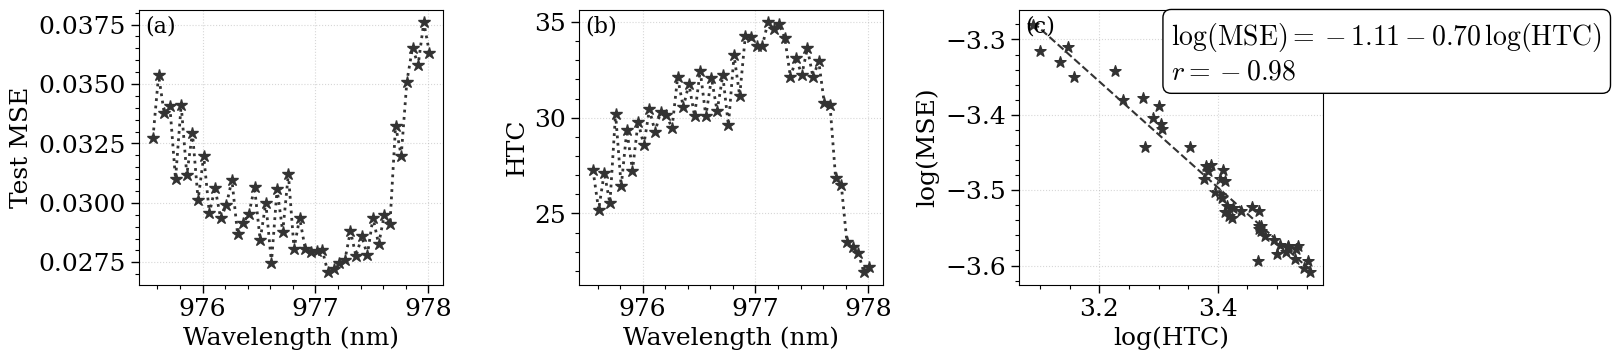

In [6]:
eps = 1e-12

wavelength = np.linspace(975.56, 978.01, len(MSE_TEST_EXP_VCS))

# ------------------------------------------------
# Experimental data for VCSEL (experiment only)
# ------------------------------------------------
log_HTC_exp_vcs      = np.log(np.asarray(HTC_EXP_VCS) + eps)
log_mse_test_exp_vcs = np.log(np.asarray(MSE_TEST_EXP_VCS) + eps)

# ------------------------------------------------
# Figure
# ------------------------------------------------
fig, axs = plt.subplots(1, 3, figsize=(16, 4))
(ax1, ax2, ax3) = axs

# =========================================================
# (a) Test MSE vs wavelength
# =========================================================
ax1.plot(wavelength, MSE_TEST_EXP_VCS,
         marker='*', linestyle=':', linewidth=2,
         label=fr'Exp. $\phi_0$', color='0.2', markersize = 9)
ax1.set_xlabel("Wavelength (nm)")
ax1.set_ylabel("Test MSE")

# =========================================================
# (b) HTC vs wavelength
# =========================================================
ax2.plot(wavelength, HTC_EXP_VCS,
         marker='*', linestyle=':', linewidth=2,
         label=fr'Exp. $\phi_0$', color='0.2', markersize = 9)
ax2.set_xlabel("Wavelength (nm)")
ax2.set_ylabel(r"HTC")

# =========================================================
# (c) log-log HTC vs MSE  (linear fit + Pearson r)
# =========================================================
slope, intercept = np.polyfit(log_HTC_exp_vcs, log_mse_test_exp_vcs, 1)
x_fit = np.linspace(min(log_HTC_exp_vcs), max(log_HTC_exp_vcs), 200)
y_fit = intercept + slope * x_fit

pearson_r = np.corrcoef(log_HTC_exp_vcs, log_mse_test_exp_vcs)[0, 1]

ax3.plot(x_fit, y_fit, linestyle='--', color='0.2', linewidth=1.5)
ax3.scatter(log_HTC_exp_vcs, log_mse_test_exp_vcs,
            marker='*', s=70, label=fr'Exp. $\phi_0$', color='0.2')
ax3.set_xlabel(r'log(HTC)')
ax3.set_ylabel(r'log(MSE)')

# ---- Equation box ----
eq_text = (
    r"$\log(\mathrm{MSE}) = "
    + (f"+ {intercept:.2f}" if intercept >= 0 else f"- {abs(intercept):.2f}")
    + f"{slope:.2f}"
    + r"\,\log(\mathrm{HTC})$"
    + "\n"
    + rf"$r = {pearson_r:.2f}$"
)
ax3.text(0.5, 0.96, eq_text,
         transform=ax3.transAxes,          # was ax4 (undefined) -> fixed
         fontsize=20, verticalalignment='top',
         bbox=dict(boxstyle="round", facecolor="white", alpha=1))

# =========================================================
# Formatting
# =========================================================
for ax in axs.flat:
    ax.minorticks_on()
    ax.xaxis.set_minor_locator(AutoMinorLocator())
    ax.yaxis.set_minor_locator(AutoMinorLocator())
    ax.tick_params(which='major', length=6, width=1)
    ax.tick_params(which='minor', length=3, width=0.8)

# Panel labels
labels = ['(a)', '(b)', '(c)']
for ax, label in zip(axs.flat, labels):
    ax.text(0.02, 0.98, label, transform=ax.transAxes, fontsize=16, va='top')

plt.tight_layout()
plt.savefig("Figure_VCSEL.pdf", bbox_inches='tight')
plt.savefig("Figure_VCSEL.png", bbox_inches='tight', dpi=400)
plt.show()